# Session 9: GUI Programming with Tkinter

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in ['gui_support.py']:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-09_first_window.py`

In [2]:
"""
Session 9 · Example 1: your first Tkinter window
------------------------------------------------
Every Tkinter program follows the same five steps:
  1. import tkinter   2. create the root window   3. create widgets
  4. place them with a geometry manager             5. start the event loop
Run:  python session-09_first_window.py
"""
from gui_support import gui_available, banner

class ClickCounter:
    """The app's logic, kept separate from the widgets so it can be tested."""
    def __init__(self):
        self.count = 0
    def click(self):
        self.count += 1
        return self.message()
    def reset(self):
        self.count = 0
        return self.message()
    def message(self):
        if self.count == 0:
            return "Click the button!"
        return f"Clicked {self.count} time{'s' if self.count != 1 else ''}" + (" - nice!" if self.count >= 5 else "")

def run_gui():
    import tkinter as tk                       # step 1
    counter = ClickCounter()
    root = tk.Tk()                             # step 2: the main window
    root.title("My first Tkinter app")
    root.geometry("320x160")                   # width x height in pixels
    root.resizable(False, False)

    label = tk.Label(root, text=counter.message(), font=("Segoe UI", 14), fg="#FF6B1A")   # step 3
    def on_click():                            # a callback: runs when the button is pressed
        label.config(text=counter.click())     # change a widget property at run time
    button = tk.Button(root, text="Click me", width=12, command=on_click)
    reset = tk.Button(root, text="Reset", command=lambda: label.config(text=counter.reset()))
    quit_btn = tk.Button(root, text="Quit", command=root.destroy)

    label.pack(pady=15)                        # step 4: pack stacks widgets top to bottom
    button.pack()
    reset.pack(side="left", padx=40, pady=10)
    quit_btn.pack(side="right", padx=40, pady=10)
    root.mainloop()                            # step 5: wait for events until the window closes

if gui_available():
    run_gui()
else:
    banner("first_window")
    c = ClickCounter()
    print("start      ->", c.message())
    for _ in range(5):
        print("click      ->", c.click())
    print("reset      ->", c.reset())
    print("\nWidgets this window creates: Tk (root), Label, Button x3")
    print("Geometry manager: pack | Event loop: root.mainloop()")

[first_window] no screen available here -> running the app logic in test mode.
Run this file on your own computer (python <file>.py) to see the window.

start      -> Click the button!
click      -> Clicked 1 time
click      -> Clicked 2 times
click      -> Clicked 3 times
click      -> Clicked 4 times
click      -> Clicked 5 times - nice!
reset      -> Click the button!

Widgets this window creates: Tk (root), Label, Button x3
Geometry manager: pack | Event loop: root.mainloop()


## Example: `session-09_widget_gallery.py`

In [3]:
"""
Session 9 · Example 2: a registration form using the common widgets
-------------------------------------------------------------------
Widgets: Label, Entry, Spinbox, Radiobutton, Checkbutton, ttk.Combobox, Listbox,
Scale, Text, Button, LabelFrame, messagebox - with Tk variable classes
(StringVar, IntVar, BooleanVar) linking widgets to Python values.
Run:  python session-09_widget_gallery.py
"""
import re
from gui_support import gui_available, banner

PROGRAMS = ["Diploma in AI", "Data Science", "Web Development"]
SKILLS = ["Python", "SQL", "Statistics", "HTML/CSS", "Git"]

def validate(form):
    """Pure function: return a list of error messages for a form dict."""
    errors = []
    if len(form["name"].strip()) < 3:
        errors.append("Name needs at least 3 characters")
    if not re.fullmatch(r"[\w.+-]+@[\w-]+\.[\w.]+", form["email"]):
        errors.append("Email is not valid")
    if not 16 <= form["age"] <= 60:
        errors.append("Age must be 16-60")
    if form["program"] not in PROGRAMS:
        errors.append("Choose a program")
    if not form["agree"]:
        errors.append("You must accept the rules")
    return errors

def summary(form):
    skills = ", ".join(form["skills"]) or "none yet"
    return (f"{form['name'].strip().title()} ({form['age']}, {form['gender']}) -> {form['program']}, "
            f"{form['shift']} shift | skills: {skills} | confidence {form['confidence']}/10")

def run_gui():
    import tkinter as tk
    from tkinter import ttk, messagebox
    root = tk.Tk(); root.title("Student registration")
    name, email = tk.StringVar(), tk.StringVar()
    age, gender, shift = tk.IntVar(value=20), tk.StringVar(value="female"), tk.StringVar(value="Morning")
    agree, confidence, program = tk.BooleanVar(), tk.IntVar(value=5), tk.StringVar()

    tk.Label(root, text="Name").grid(row=0, column=0, sticky="w", padx=6, pady=3)
    tk.Entry(root, textvariable=name, width=30).grid(row=0, column=1, columnspan=2, sticky="we")
    tk.Label(root, text="Email").grid(row=1, column=0, sticky="w", padx=6)
    tk.Entry(root, textvariable=email, width=30).grid(row=1, column=1, columnspan=2, sticky="we")
    tk.Label(root, text="Age").grid(row=2, column=0, sticky="w", padx=6)
    tk.Spinbox(root, from_=16, to=60, textvariable=age, width=5).grid(row=2, column=1, sticky="w")
    box = tk.LabelFrame(root, text="Gender"); box.grid(row=3, column=0, columnspan=3, sticky="we", padx=6)
    for g in ("female", "male", "prefer not to say"):
        tk.Radiobutton(box, text=g, value=g, variable=gender).pack(side="left")
    tk.Label(root, text="Program").grid(row=4, column=0, sticky="w", padx=6)
    ttk.Combobox(root, values=PROGRAMS, textvariable=program, state="readonly").grid(row=4, column=1, sticky="w")
    tk.Label(root, text="Shift").grid(row=5, column=0, sticky="w", padx=6)
    tk.OptionMenu(root, shift, "Morning", "Evening", "Weekend").grid(row=5, column=1, sticky="w")
    tk.Label(root, text="Skills").grid(row=6, column=0, sticky="nw", padx=6)
    skills = tk.Listbox(root, selectmode="multiple", height=5, exportselection=False)
    for s in SKILLS: skills.insert("end", s)
    skills.grid(row=6, column=1, sticky="w")
    tk.Scale(root, from_=0, to=10, orient="horizontal", label="Confidence", variable=confidence).grid(row=7, column=1, sticky="we")
    notes = tk.Text(root, height=3, width=30); notes.grid(row=8, column=1, columnspan=2, pady=3)
    tk.Checkbutton(root, text="I accept the lab rules", variable=agree).grid(row=9, column=1, sticky="w")

    def submit():
        form = {"name": name.get(), "email": email.get(), "age": age.get(), "gender": gender.get(),
                "program": program.get(), "shift": shift.get(), "agree": agree.get(),
                "skills": [skills.get(i) for i in skills.curselection()], "confidence": confidence.get(),
                "notes": notes.get("1.0", "end").strip()}
        errors = validate(form)
        if errors:
            messagebox.showerror("Please fix", "\n".join(errors))
        else:
            messagebox.showinfo("Registered", summary(form))
    tk.Button(root, text="Submit", bg="#FF6B1A", fg="white", command=submit).grid(row=10, column=1, pady=8)
    root.mainloop()

if gui_available():
    run_gui()
else:
    banner("widget_gallery")
    samples = [
        {"name": "  ayesha khan ", "email": "ayesha@example.com", "age": 21, "gender": "female",
         "program": "Diploma in AI", "shift": "Evening", "agree": True, "skills": ["Python", "SQL"], "confidence": 7},
        {"name": "Al", "email": "al@", "age": 14, "gender": "male", "program": "",
         "shift": "Morning", "agree": False, "skills": [], "confidence": 3},
    ]
    for form in samples:
        errors = validate(form)
        print("Submit pressed with:", {k: form[k] for k in ("name", "email", "age", "program")})
        print("  -> showerror:" if errors else "  -> showinfo:", "; ".join(errors) if errors else summary(form))
    print("\nWidget -> Tk variable used to read it")
    for w, v in [("Entry", "StringVar"), ("Spinbox", "IntVar"), ("Radiobutton", "StringVar (shared)"),
                 ("Checkbutton", "BooleanVar"), ("Combobox/OptionMenu", "StringVar"), ("Scale", "IntVar"),
                 ("Listbox", "curselection()"), ("Text", "get('1.0', 'end')")]:
        print(f"  {w:<20} {v}")

[widget_gallery] no screen available here -> running the app logic in test mode.
Run this file on your own computer (python <file>.py) to see the window.

Submit pressed with: {'name': '  ayesha khan ', 'email': 'ayesha@example.com', 'age': 21, 'program': 'Diploma in AI'}
  -> showinfo: Ayesha Khan (21, female) -> Diploma in AI, Evening shift | skills: Python, SQL | confidence 7/10
Submit pressed with: {'name': 'Al', 'email': 'al@', 'age': 14, 'program': ''}
  -> showerror: Name needs at least 3 characters; Email is not valid; Age must be 16-60; Choose a program; You must accept the rules

Widget -> Tk variable used to read it
  Entry                StringVar
  Spinbox              IntVar
  Radiobutton          StringVar (shared)
  Checkbutton          BooleanVar
  Combobox/OptionMenu  StringVar
  Scale                IntVar
  Listbox              curselection()
  Text                 get('1.0', 'end')


## Example: `session-09_layout_and_events.py`

In [4]:
"""
Session 9 · Example 3: grid layout, events and key bindings - a calculator
--------------------------------------------------------------------------
Shows the grid geometry manager (rows/columns, columnspan, sticky), button
commands built with lambda, and keyboard events bound with root.bind().
Run:  python session-09_layout_and_events.py
"""
from gui_support import gui_available, banner

class CalculatorEngine:
    """All calculator behaviour lives here; the GUI only forwards key presses."""
    ALLOWED = set("0123456789+-*/.()")
    def __init__(self):
        self.expr = ""
    def press(self, key):
        if key == "C":
            self.expr = ""
        elif key == "<-":
            self.expr = self.expr[:-1]
        elif key == "=":
            self.expr = self.evaluate()
        elif key in self.ALLOWED:
            if self.expr == "Error":
                self.expr = ""
            self.expr += key
        return self.expr or "0"
    def evaluate(self):
        if not self.expr or not set(self.expr) <= self.ALLOWED:      # never eval arbitrary text
            return ""
        try:
            value = eval(self.expr, {"__builtins__": {}}, {})          # only digits and operators reach here
            return str(round(value, 10)).rstrip("0").rstrip(".") if isinstance(value, float) else str(value)
        except (SyntaxError, ZeroDivisionError):
            return "Error"

LAYOUT = [["7", "8", "9", "/"],
          ["4", "5", "6", "*"],
          ["1", "2", "3", "-"],
          ["0", ".", "=", "+"],
          ["(", ")", "<-", "C"]]

def run_gui():
    import tkinter as tk
    engine = CalculatorEngine()
    root = tk.Tk(); root.title("Calculator")
    display = tk.StringVar(value="0")
    tk.Label(root, textvariable=display, anchor="e", font=("Consolas", 20), bg="#0A0716", fg="#FCD34D",
             padx=10).grid(row=0, column=0, columnspan=4, sticky="nsew")
    for r, row in enumerate(LAYOUT, start=1):
        for c, key in enumerate(row):
            tk.Button(root, text=key, font=("Segoe UI", 14), width=4,
                      command=lambda k=key: display.set(engine.press(k))   # k=key avoids late binding
                      ).grid(row=r, column=c, sticky="nsew", padx=1, pady=1)
    for i in range(4):
        root.columnconfigure(i, weight=1)                # columns stretch when resized
    def on_key(event):                                   # event object: .char, .keysym, .x, .y ...
        mapping = {"Return": "=", "BackSpace": "<-", "Escape": "C"}
        key = mapping.get(event.keysym, event.char)
        display.set(engine.press(key))
    root.bind("<Key>", on_key)
    root.mainloop()

if gui_available():
    run_gui()
else:
    banner("calculator")
    eng = CalculatorEngine()
    def type_keys(keys):
        shown = ""
        for k in keys:
            shown = eng.press(k)
        return shown
    for seq in [list("12+7*3") + ["="], ["C"] + list("(12+7)*3") + ["="], ["C"] + list("10/4") + ["="],
                ["C"] + list("9/0") + ["="], ["C"] + list("123") + ["<-", "<-"], ["C"] + list("2**3") + ["="],
                ["C", "a", "b", "5"]]:
        print(f"keys {' '.join(seq):<36} display -> {type_keys(seq)}")
    print("\nGrid plan (row, column) for the buttons:")
    for r, row in enumerate(LAYOUT, start=1):
        print("  " + "  ".join(f"[{k:>2}]({r},{c})" for c, k in enumerate(row)))

[calculator] no screen available here -> running the app logic in test mode.
Run this file on your own computer (python <file>.py) to see the window.

keys 1 2 + 7 * 3 =                        display -> 33
keys C ( 1 2 + 7 ) * 3 =                  display -> 57
keys C 1 0 / 4 =                          display -> 2.5
keys C 9 / 0 =                            display -> Error
keys C 1 2 3 <- <-                        display -> 1
keys C 2 * * 3 =                          display -> 8
keys C a b 5                              display -> 5

Grid plan (row, column) for the buttons:
  [ 7](1,0)  [ 8](1,1)  [ 9](1,2)  [ /](1,3)
  [ 4](2,0)  [ 5](2,1)  [ 6](2,2)  [ *](2,3)
  [ 1](3,0)  [ 2](3,1)  [ 3](3,2)  [ -](3,3)
  [ 0](4,0)  [ .](4,1)  [ =](4,2)  [ +](4,3)
  [ (](5,0)  [ )](5,1)  [<-](5,2)  [ C](5,3)


## Example: `session-09_problem_pos_billing.py`

In [5]:
"""
Session 9 · Real-life problem: a point-of-sale (billing) desktop app
--------------------------------------------------------------------
PROBLEM
A campus stationery shop wants a simple billing screen:
  - pick an item from a list and a quantity (Spinbox), press "Add"
  - the cart (a ttk.Treeview table) shows item, qty, price, line total
  - "Remove" deletes the selected line; a discount code can be applied
  - totals show subtotal, discount, 16 % sales tax and grand total
  - "Print receipt" writes a text receipt file
Design: a Cart class holds ALL the rules (testable without a screen);
the Tkinter layer only displays the cart and forwards button clicks.
Run:  python session-09_problem_pos_billing.py
"""
from datetime import datetime
from gui_support import gui_available, banner

CATALOGUE = {"A4 register": 180, "Ball pen (blue)": 30, "Gel pen": 60, "Highlighter": 90,
             "Geometry box": 450, "Scientific calculator": 3200, "USB drive 32GB": 1150}
CODES = {"STUDENT10": 0.10, "EID20": 0.20}
TAX = 0.16

class Cart:
    def __init__(self):
        self.lines, self.discount_code = {}, None
    def add(self, item, qty):
        if item not in CATALOGUE:
            raise ValueError(f"unknown item {item!r}")
        if not 1 <= qty <= 100:
            raise ValueError("quantity must be 1-100")
        self.lines[item] = self.lines.get(item, 0) + qty
    def remove(self, item):
        self.lines.pop(item, None)
    def apply_code(self, code):
        code = code.strip().upper()
        if code not in CODES:
            raise ValueError(f"invalid code {code!r}")
        self.discount_code = code
    def totals(self):
        sub = sum(CATALOGUE[i] * q for i, q in self.lines.items())
        disc = sub * CODES.get(self.discount_code, 0)
        tax = (sub - disc) * TAX
        return {"subtotal": sub, "discount": disc, "tax": tax, "total": round(sub - disc + tax)}
    def receipt(self, when):
        t = self.totals()
        rows = [f"{'CAMPUS STATIONERS':^40}", f"{when:%d %b %Y %H:%M}".center(40), "-" * 40]
        rows += [f"{i[:22]:<22}{q:>4} x{CATALOGUE[i]:>5} {CATALOGUE[i] * q:>7,}" for i, q in self.lines.items()]
        rows += ["-" * 40, f"{'Subtotal':<30}{t['subtotal']:>10,.0f}"]
        if t["discount"]:
            rows.append(f"{'Discount (' + self.discount_code + ')':<30}{-t['discount']:>10,.0f}")
        rows += [f"{'Sales tax 16%':<30}{t['tax']:>10,.0f}", f"{'TOTAL Rs':<30}{t['total']:>10,}", "-" * 40,
                 f"{'Thank you!':^40}"]
        return "\n".join(rows)

def run_gui():
    import tkinter as tk
    from tkinter import ttk, messagebox
    cart = Cart()
    root = tk.Tk(); root.title("Campus Stationers - POS")
    left = tk.Frame(root, padx=8, pady=8); left.pack(side="left", fill="y")
    items = tk.Listbox(left, height=8, exportselection=False)
    for name, price in CATALOGUE.items():
        items.insert("end", name)
    items.pack()
    qty = tk.Spinbox(left, from_=1, to=100, width=5); qty.pack(pady=4)
    code = tk.Entry(left, width=12); code.pack(pady=(10, 2))
    right = tk.Frame(root, padx=8, pady=8); right.pack(side="right", fill="both", expand=True)
    table = ttk.Treeview(right, columns=("qty", "price", "line"), height=8)
    for col, text in [("#0", "Item"), ("qty", "Qty"), ("price", "Price"), ("line", "Total")]:
        table.heading(col, text=text)
    table.pack(fill="both", expand=True)
    totals = tk.Label(right, justify="right", font=("Consolas", 11)); totals.pack(anchor="e")

    def refresh():
        table.delete(*table.get_children())
        for i, q in cart.lines.items():
            table.insert("", "end", iid=i, text=i, values=(q, CATALOGUE[i], CATALOGUE[i] * q))
        t = cart.totals()
        totals.config(text=f"Subtotal {t['subtotal']:>8,.0f}\nDiscount {-t['discount']:>8,.0f}\n"
                           f"Tax 16%  {t['tax']:>8,.0f}\nTOTAL    {t['total']:>8,}")
    def add():
        sel = items.curselection()
        try:
            cart.add(items.get(sel[0]) if sel else "", int(qty.get())); refresh()
        except ValueError as e:
            messagebox.showwarning("Cannot add", str(e))
    def remove():
        for iid in table.selection():
            cart.remove(iid)
        refresh()
    def apply():
        try:
            cart.apply_code(code.get()); refresh()
        except ValueError as e:
            messagebox.showerror("Discount", str(e))
    def print_receipt():
        with open("receipt.txt", "w", encoding="utf-8") as f:
            f.write(cart.receipt(datetime.now()))
        messagebox.showinfo("Receipt", "Saved to receipt.txt")
    for text, cmd in [("Add", add), ("Apply code", apply), ("Remove line", remove), ("Print receipt", print_receipt)]:
        tk.Button(left, text=text, width=14, command=cmd).pack(pady=2)
    refresh(); root.mainloop()

if gui_available():
    run_gui()
else:
    banner("pos_billing")
    cart = Cart()
    actions = [("add", "A4 register", 3), ("add", "Gel pen", 4), ("add", "Scientific calculator", 1),
               ("add", "Gel pen", 2), ("add", "Stapler", 1), ("add", "Highlighter", 0),
               ("code", "student10", None), ("code", "FREE100", None), ("remove", "A4 register", None),
               ("add", "A4 register", 2)]
    for act, arg, n in actions:
        try:
            if act == "add": cart.add(arg, n)
            elif act == "code": cart.apply_code(arg)
            else: cart.remove(arg)
            print(f"{act:<6} {arg:<22} ok      -> total Rs {cart.totals()['total']:,}")
        except ValueError as e:
            print(f"{act:<6} {arg:<22} warning -> {e}")
    print()
    print(cart.receipt(datetime(2026, 10, 26, 11, 45)))

    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    names = list(cart.lines)
    amounts = [CATALOGUE[i] * q for i, q in cart.lines.items()]
    fig, ax = plt.subplots(figsize=(6.5, 3))
    ax.barh(names, amounts, color="#FF6B1A")
    for y, a in enumerate(amounts):
        ax.text(a + 30, y, f"Rs {a:,}", va="center", fontsize=9)
    ax.set_xlim(0, max(amounts) * 1.3); ax.set_xlabel("Line total before discount and tax (Rs)")
    ax.set_title("What the customer is paying for")
    fig.tight_layout(); fig.savefig("session-09_problem_pos_billing.png", dpi=110)
    print("\nChart saved: session-09_problem_pos_billing.png")

[pos_billing] no screen available here -> running the app logic in test mode.
Run this file on your own computer (python <file>.py) to see the window.

add    A4 register            ok      -> total Rs 626
add    Gel pen                ok      -> total Rs 905
add    Scientific calculator  ok      -> total Rs 4,617
add    Gel pen                ok      -> total Rs 4,756
add    Stapler                warning -> unknown item 'Stapler'
add    Highlighter            warning -> quantity must be 1-100
code   student10              ok      -> total Rs 4,280
code   FREE100                warning -> invalid code 'FREE100'
remove A4 register            ok      -> total Rs 3,717
add    A4 register            ok      -> total Rs 4,092

           CAMPUS STATIONERS            
           26 Oct 2026 11:45            
----------------------------------------
Gel pen                  6 x   60     360
Scientific calculator    1 x 3200   3,200
A4 register              2 x  180     360
------------------


Chart saved: session-09_problem_pos_billing.png


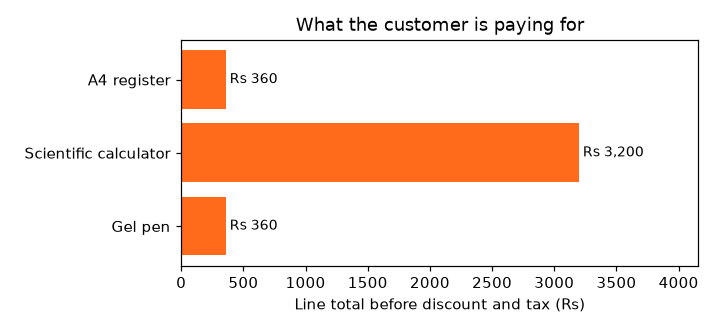

In [6]:
from IPython.display import Image, display
display(Image(filename='session-09_problem_pos_billing.png'))  # chart saved by the cell above

## Example: `session-09_project_todo_app.py`

In [7]:
"""
Session 9 · Mini project: a to-do manager desktop app with saved tasks
----------------------------------------------------------------------
Features: add tasks with a priority, mark done (double-click), delete,
filter (all / pending / done), counts in a status bar, a menu bar with
File > Save / Quit, keyboard shortcut Ctrl+S, and automatic save to a
JSON file so tasks survive restarts (Session 5).
Architecture: TodoStore (data + rules + persistence) / TodoApp (widgets).
Run:  python session-09_project_todo_app.py
"""
import json
import os
from gui_support import gui_available, banner

PRIORITIES = ["high", "normal", "low"]

class TodoStore:
    def __init__(self, path="todo.json"):
        self.path, self.tasks = path, []
        self.load()
    def load(self):
        try:
            with open(self.path, encoding="utf-8") as f:
                self.tasks = json.load(f)
        except (FileNotFoundError, json.JSONDecodeError):
            self.tasks = []
    def save(self):
        with open(self.path, "w", encoding="utf-8") as f:
            json.dump(self.tasks, f, indent=2)
    def add(self, text, priority="normal"):
        text = text.strip()
        if not text:
            raise ValueError("task text is empty")
        if priority not in PRIORITIES:
            raise ValueError(f"priority must be one of {PRIORITIES}")
        if any(t["text"].lower() == text.lower() and not t["done"] for t in self.tasks):
            raise ValueError(f"'{text}' is already on the list")
        self.tasks.append({"text": text, "priority": priority, "done": False})
        self.save()
    def toggle(self, index):
        self.tasks[index]["done"] = not self.tasks[index]["done"]; self.save()
    def delete(self, index):
        del self.tasks[index]; self.save()
    def view(self, show="all"):
        """(original_index, task) pairs, filtered and sorted: pending first, then by priority."""
        rows = [(i, t) for i, t in enumerate(self.tasks)
                if show == "all" or (show == "done") == t["done"]]
        return sorted(rows, key=lambda r: (r[1]["done"], PRIORITIES.index(r[1]["priority"])))
    def counts(self):
        done = sum(t["done"] for t in self.tasks)
        return {"total": len(self.tasks), "done": done, "pending": len(self.tasks) - done}

def label(task):
    mark = "✔" if task["done"] else "•"
    return f"{mark} [{task['priority']:>6}] {task['text']}"

class TodoApp:
    def __init__(self, store):
        import tkinter as tk
        from tkinter import messagebox
        self.tk, self.msg, self.store = tk, messagebox, store
        self.root = tk.Tk(); self.root.title("To-do manager"); self.root.geometry("440x380")
        menu = tk.Menu(self.root)
        filemenu = tk.Menu(menu, tearoff=False)
        filemenu.add_command(label="Save", accelerator="Ctrl+S", command=self.save)
        filemenu.add_separator(); filemenu.add_command(label="Quit", command=self.root.destroy)
        menu.add_cascade(label="File", menu=filemenu); self.root.config(menu=menu)
        top = tk.Frame(self.root, pady=6); top.pack(fill="x")
        self.entry = tk.Entry(top, width=28); self.entry.pack(side="left", padx=6)
        self.prio = tk.StringVar(value="normal")
        tk.OptionMenu(top, self.prio, *PRIORITIES).pack(side="left")
        tk.Button(top, text="Add", command=self.add).pack(side="left", padx=4)
        self.show = tk.StringVar(value="all")
        filt = tk.Frame(self.root); filt.pack(fill="x", padx=6)
        for s in ("all", "pending", "done"):
            tk.Radiobutton(filt, text=s, value=s, variable=self.show, command=self.refresh).pack(side="left")
        self.listbox = tk.Listbox(self.root, font=("Segoe UI", 11)); self.listbox.pack(fill="both", expand=True, padx=6)
        self.listbox.bind("<Double-Button-1>", lambda e: self.toggle())
        tk.Button(self.root, text="Delete selected", command=self.delete).pack(pady=4)
        self.status = tk.Label(self.root, anchor="w", relief="sunken"); self.status.pack(fill="x", side="bottom")
        self.root.bind("<Return>", lambda e: self.add())
        self.root.bind("<Control-s>", lambda e: self.save())
        self.rows = []; self.refresh()
    def refresh(self):
        self.listbox.delete(0, "end")
        self.rows = self.store.view(self.show.get())
        for _, t in self.rows:
            self.listbox.insert("end", label(t))
        c = self.store.counts()
        self.status.config(text=f"{c['pending']} pending | {c['done']} done | {c['total']} total")
    def selected_index(self):
        sel = self.listbox.curselection()
        return self.rows[sel[0]][0] if sel else None
    def add(self):
        try:
            self.store.add(self.entry.get(), self.prio.get()); self.entry.delete(0, "end"); self.refresh()
        except ValueError as e:
            self.msg.showwarning("To-do", str(e))
    def toggle(self):
        i = self.selected_index()
        if i is not None: self.store.toggle(i); self.refresh()
    def delete(self):
        i = self.selected_index()
        if i is not None and self.msg.askyesno("Delete", "Delete this task?"):
            self.store.delete(i); self.refresh()
    def save(self):
        self.store.save(); self.status.config(text="Saved.")

if gui_available():
    TodoApp(TodoStore()).root.mainloop()
else:
    banner("todo_app")
    path = "todo_demo.json"
    if os.path.exists(path): os.remove(path)
    store = TodoStore(path)
    for text, prio in [("Prepare Python lab 9", "high"), ("Mark quizzes", "normal"),
                       ("Buy whiteboard markers", "low"), ("  ", "normal"), ("mark quizzes", "normal"),
                       ("Email the timetable", "urgent"), ("Book projector", "high")]:
        try:
            store.add(text, prio); print(f"add {text!r:<26} ok")
        except ValueError as e:
            print(f"add {text!r:<26} warning: {e}")
    store.toggle(1)                       # double-click on "Mark quizzes"
    print("\nList (pending first, high priority first):")
    for _, t in store.view():
        print("  " + label(t))
    print("\nFilter 'done':", [t["text"] for _, t in store.view("done")])
    print("Status bar:", store.counts())
    reopened = TodoStore(path)            # simulate closing and reopening the app
    print("After restart, tasks loaded from file:", len(reopened.tasks))
    reopened.delete(0); print("After deleting the first task:", reopened.counts())
    os.remove(path)

[todo_app] no screen available here -> running the app logic in test mode.
Run this file on your own computer (python <file>.py) to see the window.

add 'Prepare Python lab 9'     ok
add 'Mark quizzes'             ok
add 'Buy whiteboard markers'   ok
add '  '                       warning: task text is empty
add 'mark quizzes'             warning: 'mark quizzes' is already on the list
add 'Email the timetable'      warning: priority must be one of ['high', 'normal', 'low']
add 'Book projector'           ok

List (pending first, high priority first):
  • [  high] Prepare Python lab 9
  • [  high] Book projector
  • [   low] Buy whiteboard markers
  ✔ [normal] Mark quizzes

Filter 'done': ['Mark quizzes']
Status bar: {'total': 4, 'done': 1, 'pending': 3}
After restart, tasks loaded from file: 4
After deleting the first task: {'total': 3, 'done': 1, 'pending': 2}
